# Problem Set 1 — Solution — Advanced Data Analytics

**HEC Lausanne, autumn 2026** · Topics: Python and NumPy, Monte Carlo
simulation, probability, numerical differentiation, feature encoding,
linear regression, constrained optimization

Based on course materials by Prof. Simon Scheidegger.

This problem set practises the content of the first lectures. Exercise 8
uses linear regression and is meant to be done **after the week-3
lecture**; everything else you can start right away.



In [1]:
import math
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures

# One random generator for the whole notebook, seeded so that results are
# reproducible: rerunning the notebook gives the same numbers.
rng = np.random.default_rng(0)


## Exercise 1 — Monte Carlo estimation of $\pi$

Monte Carlo methods are a broad class of algorithms that rely on repeated
random sampling to obtain numerical results. The classic first example is
estimating $\pi$.

Draw $N$ random points $(x, y)$ uniformly in the unit square $[0,1]^2$.
The quarter disc $x^2 + y^2 \le 1$ has area $\pi/4$, the square has area
$1$, so for large $N$

$$\frac{\text{points inside the quarter disc}}{N} \;\approx\; \frac{\pi}{4},
\qquad\text{i.e.}\qquad
\pi \approx 4 \cdot \frac{\#\{x^2 + y^2 \le 1\}}{N}.$$

![2000 random points in the unit square; the blue ones fall inside the quarter disc](figures/mc_pi.png)

The picture shows the idea with $2000$ points. Your code does not need to
draw anything: generate the pairs, count how many satisfy
$x^2 + y^2 \le 1$, multiply by four. The more samples, the more accurate
the estimate.

**Task.** Implement `estimate_pi(N)` and print a table showing how the
accuracy of the estimate improves with the number of samples, for
$N = 10^2, 10^3, \dots, 10^6$.


In [2]:
def estimate_pi(N):
    points = rng.uniform(0.0, 1.0, size=(N, 2))
    inside = np.sum(np.sum(points**2, axis=1) <= 1.0)
    return 4.0 * inside / N


estimates = {N: estimate_pi(N) for N in [10**k for k in range(2, 7)]}

print(f"{'N':>9} | {'estimate':>9} | {'|error|':>9}")
print("-" * 33)
for N, est in estimates.items():
    print(f"{N:>9} | {est:9.5f} | {abs(est - math.pi):9.5f}")


        N |  estimate |   |error|
---------------------------------
      100 |   2.92000 |   0.22159
     1000 |   3.29200 |   0.15041
    10000 |   3.14600 |   0.00441
   100000 |   3.14312 |   0.00153
  1000000 |   3.13976 |   0.00184


### Certify it

Each sample is a Bernoulli trial with success probability $p = \pi/4$, so
the estimate $4\hat p$ has standard error
$\;\mathrm{SE}(N) = 4\sqrt{p(1-p)/N}$.
A correct implementation is therefore within $4\,\mathrm{SE}(N)$ of $\pi$
essentially always (probability of a miss $\approx 6\cdot10^{-5}$ per
row), and its error shrinks like $1/\sqrt{N}$ — ten times the samples
buys you only $\sqrt{10} \approx 3.2$ times the accuracy.

**Check:** for every $N$ in your table, `assert abs(estimate - pi) < 4 * SE(N)`.


In [3]:
p = math.pi / 4
for N, est in estimates.items():
    se = 4 * math.sqrt(p * (1 - p) / N)
    assert abs(est - math.pi) < 4 * se, f"N={N}: error {abs(est - math.pi):.4f} exceeds 4 SE = {4 * se:.4f}"
    print(f"N={N:>8}: |error| = {abs(est - math.pi):.5f}  <  4 SE = {4 * se:.5f}   ok")
print("certified: errors are within 4 standard errors and shrink like 1/sqrt(N)")


N=     100: |error| = 0.22159  <  4 SE = 0.65687   ok
N=    1000: |error| = 0.15041  <  4 SE = 0.20772   ok
N=   10000: |error| = 0.00441  <  4 SE = 0.06569   ok
N=  100000: |error| = 0.00153  <  4 SE = 0.02077   ok
N= 1000000: |error| = 0.00184  <  4 SE = 0.00657   ok
certified: errors are within 4 standard errors and shrink like 1/sqrt(N)


## Exercise 2 — Flipping a coin

Write a program that simulates flipping a coin $N$ times. Print `head` or
`tail` for each flip and count the number of heads. *(Hint: draw
`r = rng.uniform()` and call it head if `r <= 0.5`, or draw an integer
from $\{1, 2\}$ with `rng.integers(1, 3)` and call it head if it is 1.)*

**Task.** Run it for $N = 20$ (printing every flip), then for
$N = 10^6$ (printing only the count and the fraction of heads).


In [4]:
def flip_coins(N, verbose=False):
    heads = 0
    for _ in range(N):
        r = rng.uniform()
        if r <= 0.5:
            heads += 1
            if verbose:
                print("head")
        elif verbose:
            print("tail")
    return heads


print(f"heads in 20 flips: {flip_coins(20, verbose=True)}")

# For a million flips a Python loop is slow; vectorise instead.
N = 1_000_000
flips = rng.uniform(size=N) <= 0.5
print(f"heads in {N} flips: {flips.sum()}  (fraction {flips.mean():.4f})")


tail
tail
tail
tail
head
tail
tail
head
tail
head
head
tail
tail
head
tail
tail
head
tail
tail
tail
heads in 20 flips: 6
heads in 1000000 flips: 500066  (fraction 0.5001)


### Certify it

The number of heads in $N$ fair flips has mean $N/2$ and standard
deviation $\sqrt{N}/2$. **Check:** for $N = 10^6$, `assert` that the
fraction of heads is within $4 \cdot 0.5/\sqrt{N} = 0.002$ of $0.5$.


In [5]:
assert abs(flips.mean() - 0.5) < 4 * 0.5 / math.sqrt(N)
print(f"certified: |{flips.mean():.4f} - 0.5| < {4 * 0.5 / math.sqrt(N):.4f}")


certified: |0.5001 - 0.5| < 0.0020


## Exercise 3 — Probabilities of rolling dice

1. You throw a die. What is the probability of getting a 6?
2. You throw a die four times in a row. What is the probability of
   getting a 6 all four times?
3. Suppose you have thrown the die three times with 6 coming up every
   time. What is the probability of getting a 6 in the fourth throw?
4. Suppose you have thrown the die 100 times and got a 6 every single
   time. What do you think about the probability of getting a 6 in the
   next throw?

**Task.** First answer the four questions from a theoretical (or
common-sense) point of view in the markdown cell below. Then write
functions that *simulate* cases 1, 2 and 3 with $N = 10^6$ trials each and
compare with your theoretical answers.


**Theory.**

1. $P(6) = 1/6 \approx 0.1667$.
2. Throws are independent, so $P(6,6,6,6) = (1/6)^4 = 1/1296 \approx 0.000772$.
3. Still $1/6$. The die has no memory: given three sixes, the fourth throw
   is an independent throw. (The $1/1296$ in question 2 is the probability
   *before* any throw is made; here three of the four are already known.)
4. Mathematically, for a *fair* die, still $1/6$. But 100 sixes in a row
   has probability $6^{-100} \approx 10^{-78}$ for a fair die — you should
   abandon the fairness assumption long before that. A sensible person
   now believes the die is loaded and puts the probability of another 6
   close to 1. This is Bayesian reasoning in a nutshell: the data update
   your belief about the model.


In [6]:
N = 1_000_000


def prob_six(N):
    rolls = rng.integers(1, 7, size=N)
    return np.mean(rolls == 6)


def prob_four_sixes(N):
    rolls = rng.integers(1, 7, size=(N, 4))
    return np.mean(np.all(rolls == 6, axis=1))


def prob_six_after_three_sixes(N):
    rolls = rng.integers(1, 7, size=(N, 4))
    first_three_are_six = np.all(rolls[:, :3] == 6, axis=1)
    fourth = rolls[first_three_are_six, 3]
    return np.mean(fourth == 6), len(fourth)


p1 = prob_six(N)
p2 = prob_four_sixes(N)
p3, n3 = prob_six_after_three_sixes(N)

print(f"P(6)                     simulated {p1:.5f}   exact {1/6:.5f}")
print(f"P(6,6,6,6)               simulated {p2:.5f}   exact {1/1296:.5f}")
print(f"P(6 | three 6s before)   simulated {p3:.5f}   exact {1/6:.5f}   (from {n3} qualifying sequences)")


P(6)                     simulated 0.16645   exact 0.16667
P(6,6,6,6)               simulated 0.00071   exact 0.00077
P(6 | three 6s before)   simulated 0.16357   exact 0.16667   (from 4677 qualifying sequences)


### Certify it

A simulated frequency of an event with probability $p$ over $n$ trials
has standard error $\sqrt{p(1-p)/n}$. **Check:** each simulated value
is within $4$ standard errors of its exact value — for case 3, $n$ is the
number of *qualifying* sequences (about $N/216 \approx 4600$), not $N$.


In [7]:
def within_4se(sim, p, n):
    return abs(sim - p) < 4 * math.sqrt(p * (1 - p) / n)


assert within_4se(p1, 1 / 6, N)
assert within_4se(p2, 1 / 1296, N)
assert within_4se(p3, 1 / 6, n3)
print("certified: all three simulated probabilities are within 4 SE of theory")


certified: all three simulated probabilities are within 4 SE of theory


## Exercise 4 — Throwing two dice

Write a program that throws two dice a large number of times. Record the
sum of the eyes each time and count how often each possible sum
$s = 2, 3, \dots, 12$ appears — a dictionary with the sum as key and the
count as value is convenient. Divide the counts by the number of trials to
get the *frequency* of each sum.

Then compute the *exact* probabilities: set up all $6 \times 6$ possible
outcomes and count how many of them have sum $s$.

**Task.** Print the frequencies and the exact probabilities side by side
for $S = 10^6$ throws.


In [8]:
S = 1_000_000

throws = rng.integers(1, 7, size=(S, 2))
sums = throws.sum(axis=1)

frequency = {}
for s in range(2, 13):
    frequency[s] = np.sum(sums == s) / S

exact = {}
for s in range(2, 13):
    exact[s] = sum(1 for i in range(1, 7) for j in range(1, 7) if i + j == s) / 36

print(f"{'sum':>4} | {'frequency':>9} | {'exact':>9}")
for s in range(2, 13):
    print(f"{s:>4} | {frequency[s]:9.5f} | {exact[s]:9.5f}")


 sum | frequency |     exact
   2 |   0.02783 |   0.02778
   3 |   0.05552 |   0.05556
   4 |   0.08322 |   0.08333
   5 |   0.11165 |   0.11111
   6 |   0.13868 |   0.13889
   7 |   0.16689 |   0.16667
   8 |   0.13859 |   0.13889
   9 |   0.11094 |   0.11111
  10 |   0.08335 |   0.08333
  11 |   0.05550 |   0.05556
  12 |   0.02783 |   0.02778


### Certify it

**Check:** the largest gap between frequency and exact probability over
$s = 2, \dots, 12$ is below $4\sqrt{p_{\max}(1-p_{\max})/S}$ with
$p_{\max} = 1/6$ (the sum $7$), i.e. below about $0.0015$ for
$S = 10^6$. Also check that both dictionaries sum to $1$.


In [9]:
worst = max(abs(frequency[s] - exact[s]) for s in range(2, 13))
tol = 4 * math.sqrt((1 / 6) * (5 / 6) / S)
assert worst < tol, f"largest gap {worst:.5f} exceeds {tol:.5f}"
assert abs(sum(frequency.values()) - 1) < 1e-12
assert abs(sum(exact.values()) - 1) < 1e-12
print(f"certified: largest gap {worst:.5f} < {tol:.5f}; both distributions sum to 1")


certified: largest gap 0.00054 < 0.00149; both distributions sum to 1


## Exercise 5 — Waves in a laboratory tank

In a laboratory experiment, waves are generated by the impact of a model
slide into a wave tank (the experiment models a future tsunami in a fjord,
triggered by rocks falling into the water). At a fixed location the
surface elevation $\eta$ is measured at discrete times with an ultrasound
gauge, giving a time series of vertical positions in metres:
$\eta(t_0), \eta(t_1), \dots, \eta(t_n)$. There are 300 observations per
second, so the time step between neighbouring measurements is
$h = 1/300$ s.

**Task.** Write code that

1. defines the time step `h` in a parameter cell (a notebook has no command
   line; a clearly marked parameter cell is the notebook equivalent);
2. reads the $\eta$ values from `data/gauge.dat` into an array `eta`;
3. plots `eta` against time;
4. computes the surface velocity by the central difference
   $$v_i \approx \frac{\eta_{i+1} - \eta_{i-1}}{2h}, \qquad i = 1, \dots, n-1,$$
   and plots it against time in a separate figure;
5. computes the surface acceleration by
   $$a_i \approx \frac{\eta_{i+1} - 2\eta_i + \eta_{i-1}}{h^2}, \qquad i = 1, \dots, n-1,$$
   and plots it against time in a separate figure.


817 measurements over 2.72 s


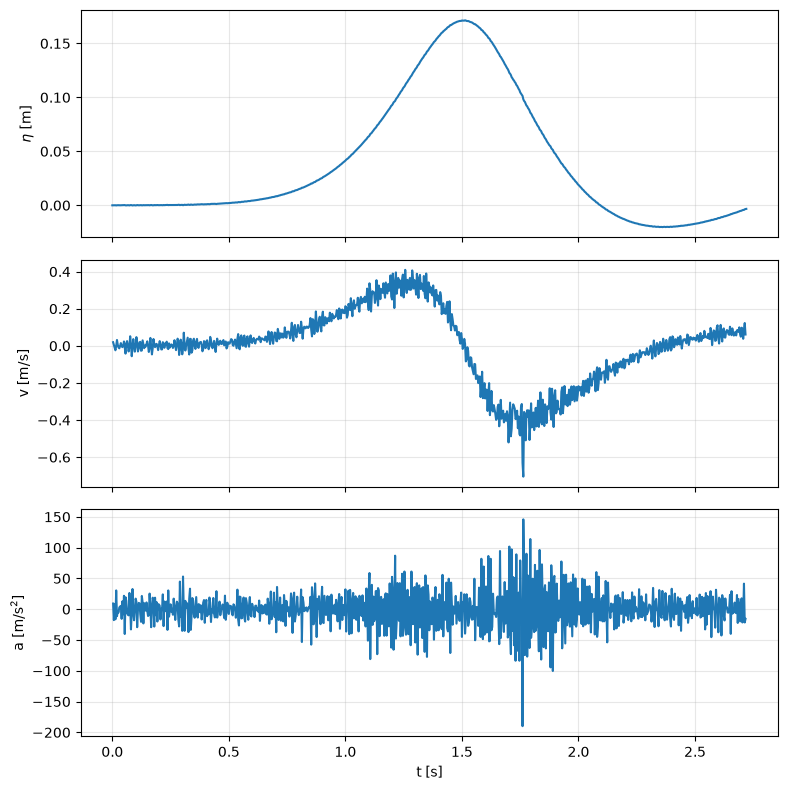

In [10]:
# --- parameters ---
h = 1 / 300  # seconds between measurements

eta = np.loadtxt("data/gauge.dat")
n = len(eta)
t = np.arange(n) * h
print(f"{n} measurements over {t[-1]:.2f} s")

velocity = (eta[2:] - eta[:-2]) / (2 * h)
acceleration = (eta[2:] - 2 * eta[1:-1] + eta[:-2]) / h**2

fig, axes = plt.subplots(3, 1, figsize=(8, 8), sharex=True)
axes[0].plot(t, eta)
axes[0].set_ylabel(r"$\eta$ [m]")
axes[1].plot(t[1:-1], velocity)
axes[1].set_ylabel("v [m/s]")
axes[2].plot(t[1:-1], acceleration)
axes[2].set_ylabel(r"a [m/s$^2$]")
axes[2].set_xlabel("t [s]")
for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Certify it

NumPy ships reference implementations of the same stencils:
`np.gradient(eta, h)` uses exactly the central difference at interior
points, and `np.diff(eta, 2) / h**2` is exactly the second difference.
**Check:** your `velocity` equals `np.gradient(eta, h)[1:-1]` and your
`acceleration` equals `np.diff(eta, 2) / h**2`, both to machine precision
(`np.allclose`). Off-by-one slices and misplaced factors of $2$ or $h$
fail this instantly.


In [11]:
assert velocity.shape == (n - 2,) and acceleration.shape == (n - 2,)
assert np.allclose(velocity, np.gradient(eta, h)[1:-1])
assert np.allclose(acceleration, np.diff(eta, 2) / h**2)
print("certified: velocity and acceleration match NumPy's reference stencils")


certified: velocity and acceleration match NumPy's reference stencils


## Exercise 6 — Differentiating noisy signals

The purpose of this exercise is to see what numerical differentiation does
to a time series that contains measurement noise. The insight will help
you interpret the velocity and acceleration plots from Exercise 5.

1. Compute the clean signal
   $$\bar\eta_i = A \sin\!\left(\frac{2\pi}{T} t_i\right), \qquad
     t_i = i\,\frac{T}{40}, \quad i = 0, \dots, 200,$$
   with $A = 1$ and $T = 2\pi$. Plot $\bar\eta$ against $t$ and store the
   values in an array `etabar`.
2. Compute a noisy signal $\eta_i = \bar\eta_i + E_i$, where the $E_i$ are
   drawn from a normal distribution with mean $0$ and standard deviation
   $\sigma = 0.04A$. Plot $\eta$ as circles in the same figure as
   $\bar\eta$. Keep the $E_i$ in an array `E` for later.
3. Compute the first derivative of $\bar\eta$ by the central difference
   $$\frac{\bar\eta_{i+1} - \bar\eta_{i-1}}{2h}, \qquad i = 1, \dots, n-1,$$
   store it in `detabar` and plot it. *What is $h$ here? Read it off the
   definition of $t_i$.*
4. Apply the same formula to the noise, $\;(E_{i+1} - E_{i-1})/2h$, store
   it in `dE`, and compute the mean and standard deviation of `dE`.
5. Plot `detabar` and `detabar + dE`. Use the standard deviations to
   explain the qualitative features of the two curves.
6. The second derivative of a signal is
   $$\frac{\eta_{i+1} - 2\eta_i + \eta_{i-1}}{h^2}, \qquad i = 1, \dots, n-1.$$
   Apply it to `etabar` (→ `d2etabar`) and to `E` (→ `d2E`). Plot
   `d2etabar` and `d2etabar + d2E`. Compute the standard deviation of
   `d2E` and compare it with those of `dE` and `E`. Discuss the plot in
   the light of these standard deviations.


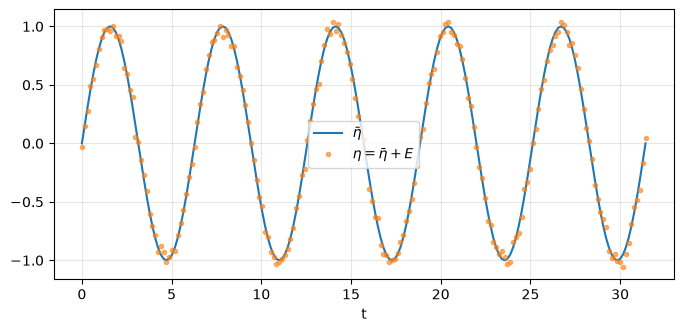

mean(dE) = +0.0012   std(dE) = 0.1853   (std(E) = 0.0393)


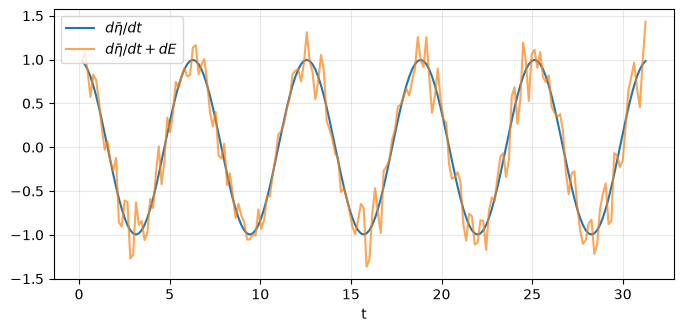

std(E) = 0.0393   std(dE) = 0.1853   std(d2E) = 3.6619


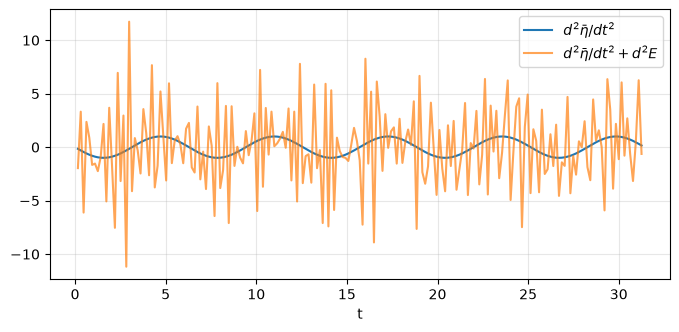

In [12]:
A = 1.0
T = 2 * math.pi
i = np.arange(201)
t = i * T / 40
h = T / 40  # t_{i+1} - t_i
sigma = 0.04 * A


def first_derivative(arr, h):
    return (arr[2:] - arr[:-2]) / (2 * h)


def second_derivative(arr, h):
    return (arr[2:] - 2 * arr[1:-1] + arr[:-2]) / h**2


# 1-2: clean and noisy signal
etabar = A * np.sin(2 * math.pi * t / T)
E = rng.normal(0.0, sigma, size=etabar.shape)
eta = etabar + E

plt.figure(figsize=(8, 3.5))
plt.plot(t, etabar, label=r"$\bar\eta$")
plt.plot(t, eta, "o", ms=3, alpha=0.6, label=r"$\eta = \bar\eta + E$")
plt.xlabel("t"); plt.legend(); plt.grid(True, alpha=0.3); plt.show()

# 3-5: first derivatives
detabar = first_derivative(etabar, h)
dE = first_derivative(E, h)
print(f"mean(dE) = {dE.mean():+.4f}   std(dE) = {dE.std():.4f}   (std(E) = {E.std():.4f})")

plt.figure(figsize=(8, 3.5))
plt.plot(t[1:-1], detabar, label=r"$d\bar\eta/dt$")
plt.plot(t[1:-1], detabar + dE, alpha=0.7, label=r"$d\bar\eta/dt + dE$")
plt.xlabel("t"); plt.legend(); plt.grid(True, alpha=0.3); plt.show()

# 6: second derivatives
d2etabar = second_derivative(etabar, h)
d2E = second_derivative(E, h)
print(f"std(E) = {E.std():.4f}   std(dE) = {dE.std():.4f}   std(d2E) = {d2E.std():.4f}")

plt.figure(figsize=(8, 3.5))
plt.plot(t[1:-1], d2etabar, label=r"$d^2\bar\eta/dt^2$")
plt.plot(t[1:-1], d2etabar + d2E, alpha=0.7, label=r"$d^2\bar\eta/dt^2 + d^2E$")
plt.xlabel("t"); plt.legend(); plt.grid(True, alpha=0.3); plt.show()


**Discussion.** With $h = T/40 \approx 0.157$ and $\sigma = 0.04$:

- **First derivative.** $dE_i = (E_{i+1} - E_{i-1})/2h$ is a difference of
  two independent $N(0, \sigma^2)$ variables divided by $2h$, so
  $\mathrm{std}(dE) = \sigma\sqrt{2}/(2h) = \sigma/(\sqrt2\,h) \approx 0.18$
  — about **4.5× the noise in the signal**, against a derivative of
  amplitude $A \cdot 2\pi/T = 1$. The curve `detabar + dE` is visibly
  rough but still recognisably a cosine.
- **Second derivative.** $d^2E_i = (E_{i+1} - 2E_i + E_{i-1})/h^2$ has
  variance $(1 + 4 + 1)\sigma^2/h^4$, so
  $\mathrm{std}(d^2E) = \sqrt6\,\sigma/h^2 \approx 4.0$ — about
  **100× the noise in the signal** and 4 times the amplitude of the true
  second derivative ($A(2\pi/T)^2 = 1$). The curve `d2etabar + d2E` is
  dominated by noise; the underlying $-\sin$ is barely visible.

Each differentiation amplifies noise by roughly $1/h$. That is why the
acceleration plot in Exercise 5 looks so much rougher than the elevation
plot: it is the same measurement noise, amplified by $1/h^2 = 90{,}000$.
Smoothing the signal before differentiating, or using a wider stencil,
is the standard remedy.


### Certify it

Two checks, one for the stencils and one for the noise statistics.

**C1 — stencils against calculus.** On the clean signal the derivatives
are known exactly: $\bar\eta' = A\frac{2\pi}{T}\cos(\frac{2\pi}{T}t)$ and
$\bar\eta'' = -A(\frac{2\pi}{T})^2\sin(\frac{2\pi}{T}t)$. Central
differences have truncation error $O(h^2)$; with $h \approx 0.157$ that
is a few $10^{-3}$. **Check:** the max absolute error of `detabar` and of
`d2etabar` against the exact derivatives at $t_1, \dots, t_{n-1}$ is
below $0.01$. A wrong $h$, a missing factor $2$, or a `/2*h` precedence
slip all produce errors of order $1$ or larger.

**C2 — noise amplification against theory.** **Check:**
`std(dE) / (sigma/(sqrt(2) h))` and `std(d2E) / (sqrt(6) sigma/h**2)`
are both between $0.8$ and $1.2$ (about 200 samples, so a 20 % band is
generous).


In [13]:
omega = 2 * math.pi / T
exact_d1 = A * omega * np.cos(omega * t[1:-1])
exact_d2 = -A * omega**2 * np.sin(omega * t[1:-1])
err1 = np.abs(detabar - exact_d1).max()
err2 = np.abs(d2etabar - exact_d2).max()
assert err1 < 0.01 and err2 < 0.01, (err1, err2)
print(f"C1  max error first derivative {err1:.2e}, second derivative {err2:.2e}  (both O(h^2))")

theory_d1 = sigma / (math.sqrt(2) * h)
theory_d2 = math.sqrt(6) * sigma / h**2
ratio1 = dE.std() / theory_d1
ratio2 = d2E.std() / theory_d2
assert 0.8 < ratio1 < 1.2 and 0.8 < ratio2 < 1.2, (ratio1, ratio2)
print(f"C2  std(dE)/theory = {ratio1:.3f}, std(d2E)/theory = {ratio2:.3f}")
print(f"    amplification factors: first derivative x{theory_d1 / sigma:.1f}, second x{theory_d2 / sigma:.1f}")
print("certified")


C1  max error first derivative 4.11e-03, second derivative 2.05e-03  (both O(h^2))
C2  std(dE)/theory = 1.029, std(d2E)/theory = 0.922
    amplification factors: first derivative x4.5, second x99.3
certified


## Exercise 7 — Kinds of features

Consider the following list of household appliances.

| Category | Price | kWh/year | Energy efficiency | Weight | Brand | Sales |
|---|---:|---:|:-:|---:|---|---:|
| Freezer | 699 | 210 | A | 99 | Mühle | 27.96 |
| Washing machine | 399 | 302 | B | 50 | Boss | 99.75 |
| Freezer | 779 | 475 | C | 75 | Nerd | 33.558 |
| Washing machine | 989 | 705 | E | 125 | Prolet | 3.996 |
| Tableware dryer | 199 | 790 | D | 42 | Boss | 2.786 |
| Tableware dryer | 479 | 810 | D | 37 | Mühle | 21.076 |

**(a)** For each of the seven features, say whether it is *nominal*,
*ordinal*, or *numerical*.

**(b)** Encode the nominal and ordinal features so that the table can be
used in a linear regression. Build the table as a `pandas.DataFrame`,
apply the encoding in code, and display the result.


**(a)**

| Feature | Kind | Why |
|---|---|---|
| Category | nominal | named groups, no order |
| Price | numerical | |
| kWh/year | numerical | |
| Energy efficiency | ordinal | A is better than B is better than C …, but the gaps are not numbers |
| Weight | numerical | |
| Brand | nominal | names, no order |
| Sales | numerical | |

**(b)** Nominal features become **dummy variables** (one 0/1 column per
category, dropping one to avoid perfect collinearity with the intercept).
Ordinal features are mapped to **integers that respect the order**
(A → 1, …, E → 5); this implicitly assumes equal gaps between adjacent
classes, which is a modelling choice worth stating.


In [14]:
appliances = pd.DataFrame({
    "category":   ["Freezer", "Washing machine", "Freezer", "Washing machine", "Tableware dryer", "Tableware dryer"],
    "price":      [699, 399, 779, 989, 199, 479],
    "kwh_year":   [210, 302, 475, 705, 790, 810],
    "efficiency": ["A", "B", "C", "E", "D", "D"],
    "weight":     [99, 50, 75, 125, 42, 37],
    "brand":      ["Mühle", "Boss", "Nerd", "Prolet", "Boss", "Mühle"],
    "sales":      [27.96, 99.75, 33.558, 3.996, 2.786, 21.076],
})

encoded = appliances.copy()
encoded["efficiency"] = encoded["efficiency"].map({"A": 1, "B": 2, "C": 3, "D": 4, "E": 5})
encoded = pd.get_dummies(encoded, columns=["category", "brand"], drop_first=True, dtype=int)
encoded


,price,kwh_year,efficiency,weight,sales,category_Tableware dryer,category_Washing machine,brand_Mühle,brand_Nerd,brand_Prolet
0,699,210,1,99,27.960,0,0,1,0,0
1,399,302,2,50,99.750,0,1,0,0,0
2,779,475,3,75,33.558,0,0,0,1,0
3,989,705,5,125,3.996,0,1,0,0,1
4,199,790,4,42,2.786,1,0,0,0,0
5,479,810,4,37,21.076,1,0,1,0,0


### Certify it

**Check:** every column of the encoded table is numeric
(`encoded.dtypes` contains no `object`/string columns), and the number of
dummy columns is (number of categories − 1) + (number of brands − 1)
$= 2 + 3 = 5$.


In [15]:
assert all(pd.api.types.is_numeric_dtype(dt) for dt in encoded.dtypes)
dummies = [c for c in encoded.columns if c.startswith(("category_", "brand_"))]
assert len(dummies) == 5, dummies
print(f"certified: {encoded.shape[1]} numeric columns, {len(dummies)} dummies: {dummies}")


certified: 10 numeric columns, 5 dummies: ['category_Tableware dryer', 'category_Washing machine', 'brand_Mühle', 'brand_Nerd', 'brand_Prolet']


## Exercise 8 — Linear regression on housing data *(after the week-3 lecture)*

`data/california_housing.csv` contains the 1990 California census: one
row per block group (20,640 rows), with these columns

| Column | Meaning |
|---|---|
| `MedInc` | median income in the block group (tens of thousands of USD) |
| `HouseAge` | median house age |
| `AveRooms`, `AveBedrms` | average rooms / bedrooms per household |
| `Population` | block-group population |
| `AveOccup` | average household size |
| `Latitude`, `Longitude` | location |
| `MedHouseVal` | **target**: median house value (hundreds of thousands of USD) |

**(a)** Look at the description of the columns and explain, for each,
whether it is nominal, ordinal, or numerical. Is there any column you
would hesitate to feed to a linear model as-is?

**(b)** Use the numerical features to fit linear models for
`MedHouseVal` with scikit-learn. Choose the features yourself — a
correlation heatmap and a few scatter plots are the tools. Split the data
into a training and a test set (80/20, fixed seed) and report the
regression coefficients, $R^2$ and the MSE **on the test set**. Do not
only fit a linear model: also fit a model with second-order polynomial
features and compare.

**(c)** Implement the linear regression yourself, using the closed form
derived in the lecture,
$$\mathbf{w} = (\mathbf{X}^\top \mathbf{X})^{-1}\mathbf{X}^\top \mathbf{y},$$
with a column of ones in $\mathbf{X}$ for the intercept. Compare the
parameters, $R^2$ and MSE with those from (b).


**(a)** Every column is **numerical** — this dataset has no nominal or
ordinal features. Two deserve a second look before going into a linear
model:

- `Latitude` and `Longitude` are numbers, but "one degree further north"
  has no monotone meaning for house prices — the effect of location is
  about *where* you are (coast vs inland, near a city), which a linear
  term captures only crudely. They work better through interactions,
  polynomial terms, or a distance-to-city feature.
- `AveRooms`, `AveBedrms`, `AveOccup` and `Population` have extreme
  outliers (some block groups are hotels, prisons, or nearly empty);
  a linear fit is sensitive to those. Checking `describe()` before fitting
  is the habit to build.


In [16]:
housing = pd.read_csv("data/california_housing.csv")
housing.describe().T


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


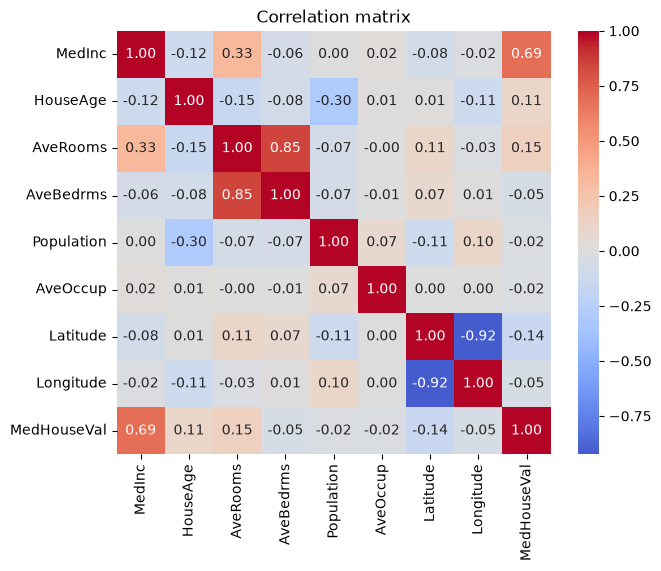

Linear model
      MedInc: +0.4335
    HouseAge: +0.0095
    AveRooms: -0.0983
   AveBedrms: +0.5928
    AveOccup: -0.0049
    Latitude: -0.4202
   Longitude: -0.4332
   intercept: -36.8074
  test R^2 = 0.5945   test MSE = 0.5288



Quadratic model on ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'AveOccup', 'Latitude', 'Longitude']
  35 features   test R^2 = -1.0287   test MSE = 2.6453

Quadratic model on ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Latitude', 'Longitude']
  27 features   test R^2 = 0.6423   test MSE = 0.4664


In [17]:
plt.figure(figsize=(7, 5.5))
sns.heatmap(housing.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

# MedInc is by far the strongest single predictor; location and house age
# add a little. AveBedrms/AveRooms are useful mainly together.
features = ["MedInc", "HouseAge", "AveRooms", "AveBedrms", "AveOccup", "Latitude", "Longitude"]
X = housing[features]
y = housing["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

linear = LinearRegression().fit(X_train, y_train)
pred_lin = linear.predict(X_test)
r2_lin = r2_score(y_test, pred_lin)
mse_lin = mean_squared_error(y_test, pred_lin)

print("Linear model")
for name, coef in zip(features, linear.coef_):
    print(f"  {name:>10}: {coef:+.4f}")
print(f"  {'intercept':>10}: {linear.intercept_:+.4f}")
print(f"  test R^2 = {r2_lin:.4f}   test MSE = {mse_lin:.4f}")

# Second-order polynomial features (squares and pairwise products)
def fit_quadratic(feature_list):
    poly = PolynomialFeatures(degree=2, include_bias=False)
    Xtr = poly.fit_transform(X_train[feature_list])
    Xte = poly.transform(X_test[feature_list])
    model = LinearRegression().fit(Xtr, y_train)
    pred = model.predict(Xte)
    print(f"Quadratic model on {feature_list}")
    print(f"  {Xtr.shape[1]} features   test R^2 = {r2_score(y_test, pred):.4f}   test MSE = {mean_squared_error(y_test, pred):.4f}")
    return model


print()
quadratic_all = fit_quadratic(features)
print()
quadratic = fit_quadratic([f for f in features if f != "AveOccup"])


**Reading the results.** Median income alone explains most of what a
linear model can explain; location and house age add a little.

The first quadratic fit is a lesson in itself: **test $R^2$ is negative**
— the model is worse than predicting the mean. Nothing is wrong with the
code. Part (a) flagged `AveOccup` as having absurd outliers (a block
group with 1,243 average occupants — an institution, not housing);
squaring such a value produces a feature six orders of magnitude larger
than everything else, the fit bends to accommodate a handful of training
rows, and a test row in the same tail sends the prediction off the
scale. More flexible models amplify data problems.

Without `AveOccup` the quadratic model does what one hopes: test $R^2$
rises from $0.59$ to $0.64$, mostly because the `Latitude × Longitude`
products and squares start to capture *where* the coast and the cities
are. Both models remain far from perfect — house values are top-coded at
5, and the relationship with location is not polynomial. That gap is what
the non-linear methods later in the course are for.


In [18]:
def ols_closed_form(X, y):
    X1 = np.column_stack([np.ones(len(X)), np.asarray(X)])
    # w = (X^T X)^{-1} X^T y, computed by solving the normal equations
    # rather than forming the inverse explicitly.
    return np.linalg.solve(X1.T @ X1, X1.T @ np.asarray(y))


def predict_closed_form(w, X):
    X1 = np.column_stack([np.ones(len(X)), np.asarray(X)])
    return X1 @ w


w = ols_closed_form(X_train, y_train)
pred_manual = predict_closed_form(w, X_test)
r2_manual = 1 - np.sum((y_test - pred_manual) ** 2) / np.sum((y_test - y_test.mean()) ** 2)
mse_manual = np.mean((y_test - pred_manual) ** 2)

comparison = pd.DataFrame(
    {"sklearn": np.concatenate([[linear.intercept_], linear.coef_]), "closed form": w},
    index=["intercept"] + features,
)
comparison["abs diff"] = (comparison["sklearn"] - comparison["closed form"]).abs()
print(comparison.to_string(float_format=lambda v: f"{v:+.6f}"))
print(f"\ntest R^2: sklearn {r2_lin:.6f}   closed form {r2_manual:.6f}")
print(f"test MSE: sklearn {mse_lin:.6f}   closed form {mse_manual:.6f}")


             sklearn  closed form  abs diff
intercept -36.807365   -36.807365 +0.000000
MedInc     +0.433460    +0.433460 +0.000000
HouseAge   +0.009524    +0.009524 +0.000000
AveRooms   -0.098289    -0.098289 +0.000000
AveBedrms  +0.592762    +0.592762 +0.000000
AveOccup   -0.004851    -0.004851 +0.000000
Latitude   -0.420203    -0.420203 +0.000000
Longitude  -0.433208    -0.433208 +0.000000

test R^2: sklearn 0.594472   closed form 0.594472
test MSE: sklearn 0.528791   closed form 0.528791


### Certify it

**Check:** your closed-form parameters agree with scikit-learn's to
$10^{-6}$ (absolute), and $R^2$ and MSE agree to $10^{-9}$. If the
intercept is off but the slopes agree, the column of ones is missing; if
everything is off, the formula is applied to the wrong matrix or the
wrong split.


In [19]:
assert comparison["abs diff"].max() < 1e-6, comparison["abs diff"].max()
assert abs(r2_manual - r2_lin) < 1e-9 and abs(mse_manual - mse_lin) < 1e-9
print(f"certified: max parameter gap {comparison['abs diff'].max():.1e}; R^2 and MSE identical")


certified: max parameter gap 1.6e-09; R^2 and MSE identical


## Exercise 9 — Constrained optimization

Solve the following problem with a Python optimization toolkit of your
choice (`scipy.optimize.minimize` with `method="trust-constr"` is a good
default):

$$\begin{aligned}
\min_{x}\quad & x_1 x_4 (x_1 + x_2 + x_3) + x_3 && \text{objective}\\
\text{s.t.}\quad & x_1 x_2 x_3 x_4 \ge 25 && \text{inequality constraint}\\
& x_1^2 + x_2^2 + x_3^2 + x_4^2 = 40 && \text{equality constraint}\\
& 1 \le x_1, x_2, x_3, x_4 \le 5 && \text{bounds}\\
& x^{(0)} = (1, 5, 5, 1) && \text{initial guess}
\end{aligned}$$

Solve it twice:

- **(i)** providing the **analytical** gradient and Hessian of the
  objective (derive them by hand in the markdown cell);
- **(ii)** providing a **first-order finite-difference** implementation
  of the gradient and Hessian that you write yourself, i.e.
  $\partial_i f(x) \approx \bigl(f(x + h e_i) - f(x)\bigr)/h$ and the
  Hessian by differencing that gradient again.

Compare the results of (i) and (ii): the optimum found, the number of
iterations, and the running time. What do you observe?

*(The constraints' derivatives are simple; give them analytically in both
runs so that the comparison isolates the objective's derivatives.)*


**Derivatives of** $f(x) = x_1 x_4 (x_1 + x_2 + x_3) + x_3$:

$$\nabla f(x) = \begin{pmatrix}
x_4\,(2x_1 + x_2 + x_3)\\ x_1 x_4\\ x_1 x_4 + 1\\ x_1\,(x_1 + x_2 + x_3)
\end{pmatrix}, \qquad
\nabla^2 f(x) = \begin{pmatrix}
2x_4 & x_4 & x_4 & 2x_1 + x_2 + x_3\\
x_4 & 0 & 0 & x_1\\
x_4 & 0 & 0 & x_1\\
2x_1 + x_2 + x_3 & x_1 & x_1 & 0
\end{pmatrix}.$$

Constraints: $\nabla(x_1 x_2 x_3 x_4) = (x_2 x_3 x_4,\; x_1 x_3 x_4,\;
x_1 x_2 x_4,\; x_1 x_2 x_3)$ and $\nabla(\sum x_i^2) = 2x$.


In [20]:
def f(x):
    return x[0] * x[3] * (x[0] + x[1] + x[2]) + x[2]


def grad_f(x):
    return np.array([
        x[3] * (2 * x[0] + x[1] + x[2]),
        x[0] * x[3],
        x[0] * x[3] + 1,
        x[0] * (x[0] + x[1] + x[2]),
    ])


def hess_f(x):
    s = 2 * x[0] + x[1] + x[2]
    return np.array([
        [2 * x[3], x[3], x[3], s],
        [x[3], 0, 0, x[0]],
        [x[3], 0, 0, x[0]],
        [s, x[0], x[0], 0],
    ])


def fd_grad(x, h=1e-6):
    g = np.zeros(4)
    fx = f(x)
    for i in range(4):
        e = np.zeros(4)
        e[i] = h
        g[i] = (f(x + e) - fx) / h
    return g


def fd_hess(x, h=1e-4):
    H = np.zeros((4, 4))
    g = fd_grad(x)
    for i in range(4):
        e = np.zeros(4)
        e[i] = h
        H[:, i] = (fd_grad(x + e) - g) / h
    return 0.5 * (H + H.T)  # symmetrise: forward differences are not exactly symmetric


constraints = [
    {"type": "ineq", "fun": lambda x: np.prod(x) - 25,
     "jac": lambda x: np.array([x[1] * x[2] * x[3], x[0] * x[2] * x[3], x[0] * x[1] * x[3], x[0] * x[1] * x[2]])},
    {"type": "eq", "fun": lambda x: np.sum(x**2) - 40, "jac": lambda x: 2 * x},
]
bounds = [(1, 5)] * 4
x0 = np.array([1.0, 5.0, 5.0, 1.0])


f_plain = f
n_evals = 0  # counts every evaluation of the objective, including those inside fd_grad/fd_hess


def f_counted(x):
    global n_evals
    n_evals += 1
    return f_plain(x)


def solve(jac, hess, label):
    global n_evals
    n_evals = 0
    start = time.perf_counter()
    res = minimize(f_counted, x0, jac=jac, hess=hess, constraints=constraints, bounds=bounds,
                   method="trust-constr", options={"gtol": 1e-8, "xtol": 1e-10})
    elapsed = time.perf_counter() - start
    print(f"{label}")
    print(f"  x*   = {np.round(res.x, 6)}")
    print(f"  f(x*) = {res.fun:.6f}   iterations = {res.nit}   time = {elapsed * 1e3:.1f} ms   success = {res.success}")
    return res


# fd_grad / fd_hess call f directly; route them through the counter too
f = f_counted
res_analytic = solve(grad_f, hess_f, "(i)  analytical gradient and Hessian")
evals_analytic = n_evals
res_fd = solve(fd_grad, fd_hess, "(ii) finite-difference gradient and Hessian")
evals_fd = n_evals
f = f_plain
print(f"\nobjective evaluations: analytical {evals_analytic}, finite-difference {evals_fd}")


(i)  analytical gradient and Hessian
  x*   = [1.       4.742999 3.82115  1.379408]
  f(x*) = 17.014018   iterations = 26   time = 10.9 ms   success = True
(ii) finite-difference gradient and Hessian
  x*   = [1.       4.742999 3.82115  1.379408]
  f(x*) = 17.014018   iterations = 25   time = 9.6 ms   success = True

objective evaluations: analytical 18, finite-difference 527


**Observation.** Both runs reach the same optimum,
$x^* \approx (1.000, 4.743, 3.821, 1.379)$ with $f(x^*) = 17.0140$ — the
well-known solution of this textbook problem (it is *HS071* from the
Hock–Schittkowski test set). The iteration counts and wall-clock times
are similar; the difference is hidden in the **number of objective
evaluations**: each finite-difference gradient costs 5 evaluations of
$f$ and each Hessian about 25, so run (ii) evaluates $f$ many times more
often than run (i). For a 4-variable polynomial that is microseconds;
for a model that takes seconds per evaluation, or thousands of
variables, it is the difference between feasible and not. Forward
differences also carry an $O(h)$ truncation error that the optimizer's
convergence test has to live with — here harmless, as the certification
below shows, but it caps the attainable precision.


### Certify it

**C1 — derivatives.** At $x^{(0)}$, your finite-difference gradient must
agree with the analytical one to about $10^{-5}$ and the finite-difference
Hessian to about $10^{-3}$ (forward differences: error $\sim h$). A sign
error or a swapped index shows up as a disagreement of order $1$.

**C2 — the optimum.** Both runs must satisfy the constraints and land on
$f(x^*) = 17.014017$ to within $10^{-4}$, with
$x^* = (1.0000, 4.7430, 3.8212, 1.3794)$ to within $10^{-3}$.


In [21]:
grad_gap = np.abs(fd_grad(x0) - grad_f(x0)).max()
hess_gap = np.abs(fd_hess(x0) - hess_f(x0)).max()
assert grad_gap < 1e-5 and hess_gap < 1e-3, (grad_gap, hess_gap)
print(f"C1  |fd_grad - grad_f| = {grad_gap:.1e}   |fd_hess - hess_f| = {hess_gap:.1e}")

x_star = np.array([1.0, 4.7429994, 3.8211503, 1.3794082])
f_star = 17.0140173
for label, res in [("analytical", res_analytic), ("finite-difference", res_fd)]:
    assert abs(res.fun - f_star) < 1e-4, (label, res.fun)
    assert np.abs(res.x - x_star).max() < 1e-3, (label, res.x)
    assert np.prod(res.x) >= 25 - 1e-6 and abs(np.sum(res.x**2) - 40) < 1e-6, label
    print(f"C2  {label:>17}: |f - f*| = {abs(res.fun - f_star):.1e}, |x - x*| = {np.abs(res.x - x_star).max():.1e}, constraints ok")
print("certified")


C1  |fd_grad - grad_f| = 1.0e-06   |fd_hess - hess_f| = 5.4e-05
C2         analytical: |f - f*| = 5.0e-07, |x - x*| = 2.6e-07, constraints ok
C2  finite-difference: |f - f*| = 6.6e-07, |x - x*| = 1.2e-07, constraints ok
certified


### Bonus — automatic differentiation

Deriving gradients and Hessians by hand is error-prone (that is what C1
is for). Modern tools do it exactly, by tracing the program: with JAX,
`jax.grad(f)` and `jax.hessian(f)` return functions that evaluate the
derivatives to machine precision — no $h$, no truncation error.

**Task.** Compute the gradient and Hessian of $f$ at $x^{(0)}$ with JAX
and check them against your analytical ones (they should agree to
$\sim 10^{-6}$ in single precision, $10^{-12}$ if you enable float64).


In [22]:
try:
    import jax
    import jax.numpy as jnp

    jax.config.update("jax_enable_x64", True)

    def f_jax(x):
        return x[0] * x[3] * (x[0] + x[1] + x[2]) + x[2]

    x0_j = jnp.asarray(x0)
    g_auto = np.asarray(jax.grad(f_jax)(x0_j))
    H_auto = np.asarray(jax.hessian(f_jax)(x0_j))
    print(f"|jax.grad - grad_f|    = {np.abs(g_auto - grad_f(x0)).max():.1e}")
    print(f"|jax.hessian - hess_f| = {np.abs(H_auto - hess_f(x0)).max():.1e}")
    assert np.allclose(g_auto, grad_f(x0), atol=1e-10)
    assert np.allclose(H_auto, hess_f(x0), atol=1e-10)
    print("certified: automatic differentiation reproduces the hand derivatives exactly")
except ImportError:
    print("JAX is not installed in this environment — skip the bonus, or `pip install jax`.")


|jax.grad - grad_f|    = 0.0e+00
|jax.hessian - hess_f| = 0.0e+00
certified: automatic differentiation reproduces the hand derivatives exactly
